<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_field_theory/sft_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Field Theory* — `sft_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SFT Ch 2 Figures — Colab Notebook
**Statistical Field Theory · Chapter 2: My First Path Integral**

PSE Lab · SeoulTech · Tong (Cambridge)

Figures saved to `figures/ch02/`. Run each cell independently.

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | Gaussian path integral, fluctuation $f$, heat capacity $C$ | §2.1 |
| fig02 | $G(r)$, $G(k)$, $S(q)$ — Ornstein-Zernike | §2.2 |
| fig03 | $\xi(T)$, critical $G(r)$, $\chi(T)$ | §2.2–2.3 |
| fig04 | QFT analogy + crossover at $d_{uc}=4$ | §2.5 |
| fig05 | Ginzburg criterion + Gaussian $C$ | §2.4 |

---
## fig01 · Gaussian Path Integral (§2.1)

**Left**: Gaussian weight $e^{-\beta F}$ broadens as $\mu^2\to0$ near $T_c$. **Centre**: Fluctuation free energy $\delta f\sim\xi^{-d}\sim|t|^{d/2}$. **Right**: Heat capacity $C\sim|t|^{-\alpha}$ with $\alpha_G=2-d/2$.

  saved -> figures/ch02/fig01_path_integral.png


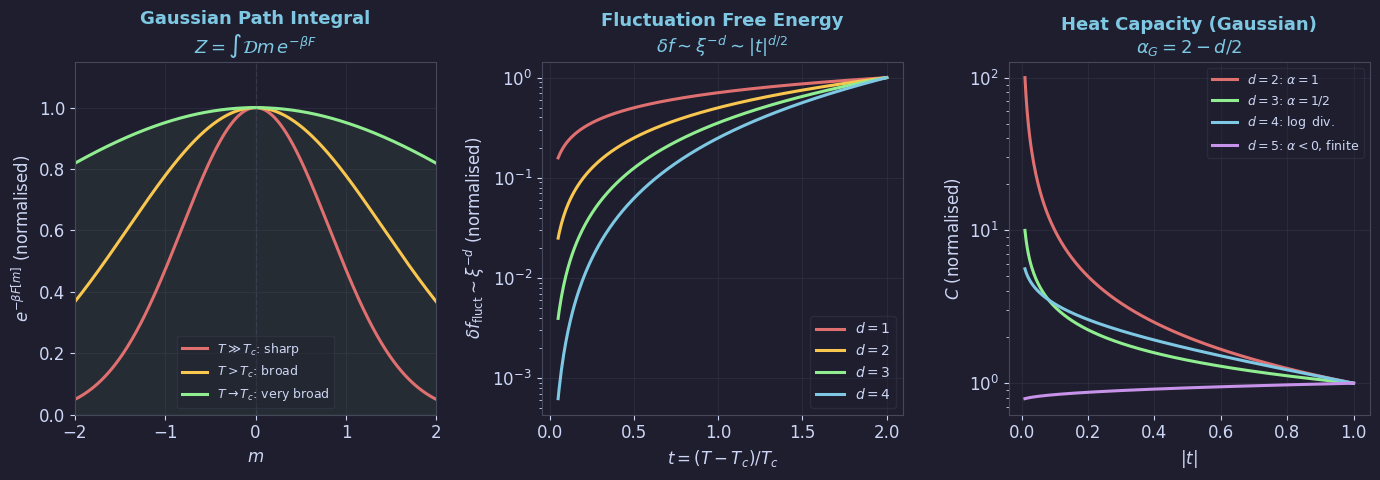

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01: Gaussian Path Integral (Ch 2.1) ────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Panel 1: Gaussian weight broadening near T_c
ax = axes[0]
m = np.linspace(-2, 2, 500)
for mu2, col, lab in [(1.5,RED,r'$T\gg T_c$: sharp'),
                       (0.5,YELLOW,r'$T>T_c$: broad'),
                       (0.1,GREEN,r'$T\to T_c$: very broad')]:
    w = np.exp(-mu2*m**2/2); w /= w.max()
    ax.plot(m, w, color=col, lw=2.2, label=lab)
ax.axvline(0, color=EDGE, lw=1.0, ls='--', alpha=0.5)
ax.fill_between(m, 0, np.exp(-0.1*m**2/2), color=GREEN, alpha=0.07)
ax.set_xlabel(r'$m$'); ax.set_ylabel(r'$e^{-\beta F[m]}$ (normalised)')
ax.set_title(r'Gaussian Path Integral'+'\n'+r'$Z=\int\mathcal{D}m\,e^{-\beta F}$',
             color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(-2,2); ax.set_ylim(0,1.15)

# Panel 2: fluctuation free energy vs t
ax2 = axes[1]
t_arr = np.linspace(0.05, 2.0, 300)
for d, col, lab in [(1,RED,r'$d=1$'),(2,YELLOW,r'$d=2$'),
                     (3,GREEN,r'$d=3$'),(4,BLUE,r'$d=4$')]:
    df = t_arr**(d*0.5); df /= df[-1]
    ax2.semilogy(t_arr, df, color=col, lw=2.2, label=lab)
ax2.set_xlabel(r'$t=(T-T_c)/T_c$')
ax2.set_ylabel(r'$\delta f_{\rm fluct}\sim\xi^{-d}$ (normalised)')
ax2.set_title(r'Fluctuation Free Energy'+'\n'+r'$\delta f\sim\xi^{-d}\sim|t|^{d/2}$',
             color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG); ax2.grid(True)

# Panel 3: heat capacity from Gaussian theory
ax3 = axes[2]
t_plot = np.linspace(0.01, 1.0, 300)
for d, col, lab in [(2,RED,r'$d=2$: $\alpha=1$'),
                     (3,GREEN,r'$d=3$: $\alpha=1/2$'),
                     (4,BLUE,r'$d=4$: $\log$ div.'),
                     (5,PURPLE,r'$d=5$: $\alpha<0$, finite')]:
    alpha = 2 - d/2
    if alpha > 0:
        C = t_plot**(-alpha)
    elif alpha == 0:
        C = -np.log(t_plot) + 1
    else:
        C = 1 + 0.3*t_plot**(-alpha)
    C_norm = C/C[-1]
    ax3.semilogy(t_plot, C_norm, color=col, lw=2.2, label=lab)
ax3.set_xlabel(r'$|t|$'); ax3.set_ylabel(r'$C$ (normalised)')
ax3.set_title(r'Heat Capacity (Gaussian)'+'\n'+r'$\alpha_G=2-d/2$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.2)
save('fig01_path_integral.png', fig)


---
## fig02 · Correlation Functions (§2.2)

**Left**: $G(r)$ — exponential for $\xi<\infty$, power-law at criticality. **Centre**: Propagator $G(k)=(k^2+\mu^2)^{-1}$ — Lorentzian. **Right**: Structure factor $S(q)$ — Ornstein-Zernike peak sharpens as $\xi$ grows.

  saved -> figures/ch02/fig02_correlation_fns.png


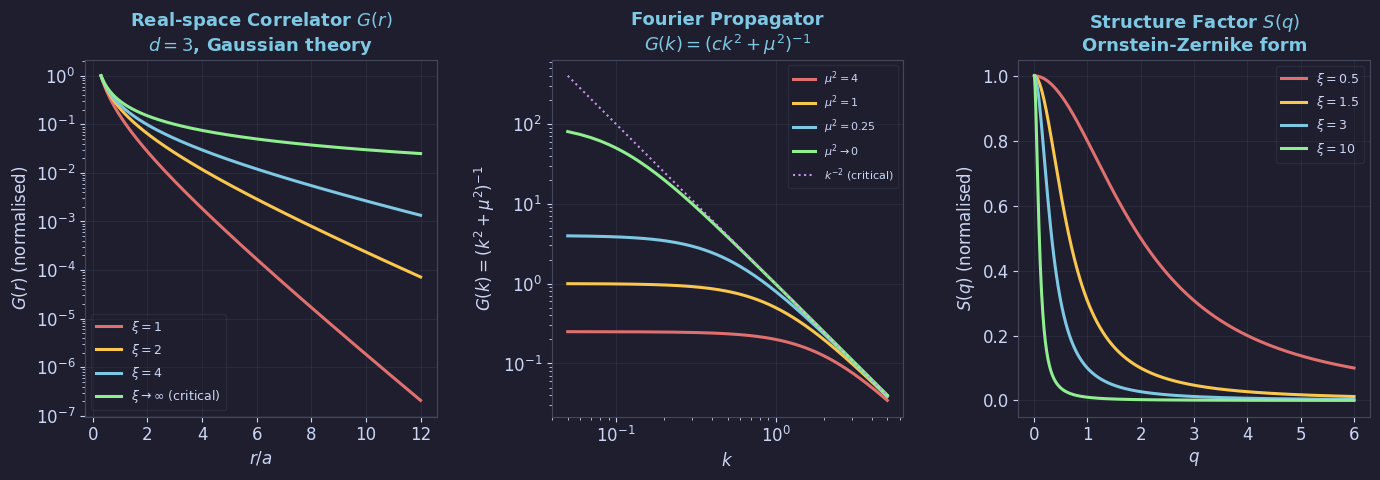

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02: Correlation Functions G(r), G(k), S(q) (Ch 2.2) ───────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
r = np.linspace(0.3, 12, 500)

ax = axes[0]
for xi, col, lab in [(1.0,RED,r'$\xi=1$'),(2.0,YELLOW,r'$\xi=2$'),
                      (4.0,BLUE,r'$\xi=4$'),(50,GREEN,r'$\xi\to\infty$ (critical)')]:
    G = np.exp(-r/xi)/r if xi < 10 else r**(-1)
    G /= G[0]
    ax.semilogy(r, G, color=col, lw=2.2, label=lab)
ax.set_xlabel(r'$r/a$'); ax.set_ylabel(r'$G(r)$ (normalised)')
ax.set_title(r'Real-space Correlator $G(r)$'+'\n'+r'$d=3$, Gaussian theory', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)

ax2 = axes[1]
k = np.linspace(0.05, 5, 500)
for mu2, col, lab in [(4.0,RED,r'$\mu^2=4$'),(1.0,YELLOW,r'$\mu^2=1$'),
                       (0.25,BLUE,r'$\mu^2=0.25$'),(0.01,GREEN,r'$\mu^2\to0$')]:
    ax2.loglog(k, 1/(k**2+mu2), color=col, lw=2.2, label=lab)
ax2.loglog(k, k**(-2), color=PURPLE, lw=1.5, ls=':', label=r'$k^{-2}$ (critical)')
ax2.set_xlabel(r'$k$'); ax2.set_ylabel(r'$G(k)=(k^2+\mu^2)^{-1}$')
ax2.set_title(r'Fourier Propagator'+'\n'+r'$G(k)=(ck^2+\mu^2)^{-1}$', color=BLUE)
ax2.legend(fontsize=8, labelcolor=FG); ax2.grid(True)

ax3 = axes[2]
q = np.linspace(0.01, 6, 500)
for xi_v, col, lab in [(0.5,RED,r'$\xi=0.5$'),(1.5,YELLOW,r'$\xi=1.5$'),
                        (3.0,BLUE,r'$\xi=3$'),(10.0,GREEN,r'$\xi=10$')]:
    Sq = xi_v**2/(1+(q*xi_v)**2)
    ax3.plot(q, Sq/Sq.max(), color=col, lw=2.2, label=lab)
ax3.set_xlabel(r'$q$'); ax3.set_ylabel(r'$S(q)$ (normalised)')
ax3.set_title(r'Structure Factor $S(q)$'+'\nOrnstein-Zernike form', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.2)
save('fig02_correlation_fns.png', fig)


---
## fig03 · Scaling of $\xi$, $G(r)|_{T_c}$, $\chi$ (§2.2–2.3)

**Left**: $\xi\sim|t|^{-\nu}$ for MFT, 3D Ising, 2D Ising, 3D XY. **Centre**: Critical correlator $G(r)\sim r^{-(d-2+\eta)}$ — anomalous dimension $\eta>0$ for interacting theories. **Right**: $\chi\sim|t|^{-\gamma}$.

  saved -> figures/ch02/fig03_xi_scaling.png


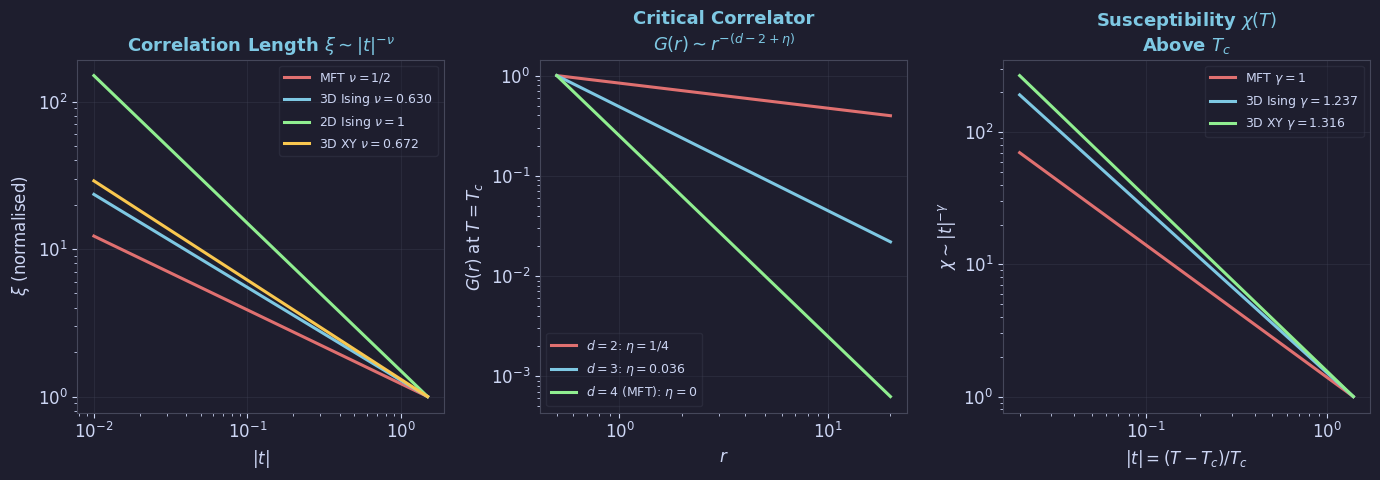

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03: xi(T), G(r)|Tc, chi(T) (Ch 2.2–2.3) ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

ax = axes[0]
t_arr = np.linspace(0.01, 1.5, 300)
for nu, col, lab in [(0.5,RED,r'MFT $\nu=1/2$'),
                      (0.630,BLUE,r'3D Ising $\nu=0.630$'),
                      (1.0,GREEN,r'2D Ising $\nu=1$'),
                      (0.672,YELLOW,r'3D XY $\nu=0.672$')]:
    xi = t_arr**(-nu); xi /= xi[-1]
    ax.loglog(t_arr, xi, color=col, lw=2.2, label=lab)
ax.set_xlabel(r'$|t|$'); ax.set_ylabel(r'$\xi$ (normalised)')
ax.set_title(r'Correlation Length $\xi\sim|t|^{-\nu}$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)

ax2 = axes[1]
r2 = np.linspace(0.5, 20, 500)
for d, eta, col, lab in [(2, 0.25, RED, r'$d=2$: $\eta=1/4$'),
                           (3, 0.036, BLUE, r'$d=3$: $\eta=0.036$'),
                           (4, 0.0, GREEN, r'$d=4$ (MFT): $\eta=0$')]:
    G = r2**(-(d-2+eta)); G /= G[0]
    ax2.loglog(r2, G, color=col, lw=2.2, label=lab)
ax2.set_xlabel(r'$r$'); ax2.set_ylabel(r'$G(r)$ at $T=T_c$')
ax2.set_title(r'Critical Correlator'+'\n'+r'$G(r)\sim r^{-(d-2+\eta)}$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)

ax3 = axes[2]
t_arr3 = np.linspace(0.02, 1.4, 300)
for gamma, col, lab in [(1.0, RED, r'MFT $\gamma=1$'),
                          (1.237, BLUE, r'3D Ising $\gamma=1.237$'),
                          (1.316, GREEN, r'3D XY $\gamma=1.316$')]:
    chi = t_arr3**(-gamma); chi /= chi[-1]
    ax3.loglog(t_arr3, chi, color=col, lw=2.2, label=lab)
ax3.set_xlabel(r'$|t|=(T-T_c)/T_c$'); ax3.set_ylabel(r'$\chi\sim|t|^{-\gamma}$')
ax3.set_title(r'Susceptibility $\chi(T)$'+'\nAbove $T_c$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.2)
save('fig03_xi_scaling.png', fig)


---
## fig04 · QFT Analogy & Crossover at $d_{uc}=4$ (§2.5)

**Left**: SFT propagator is identical to Euclidean QFT propagator — $\beta F_{\rm SFT}=S_E^{\rm QFT}$. **Right**: Critical exponents interpolate between WF fixed point ($d<4$) and MFT ($d>4$).

  saved -> figures/ch02/fig04_qft_analogy.png


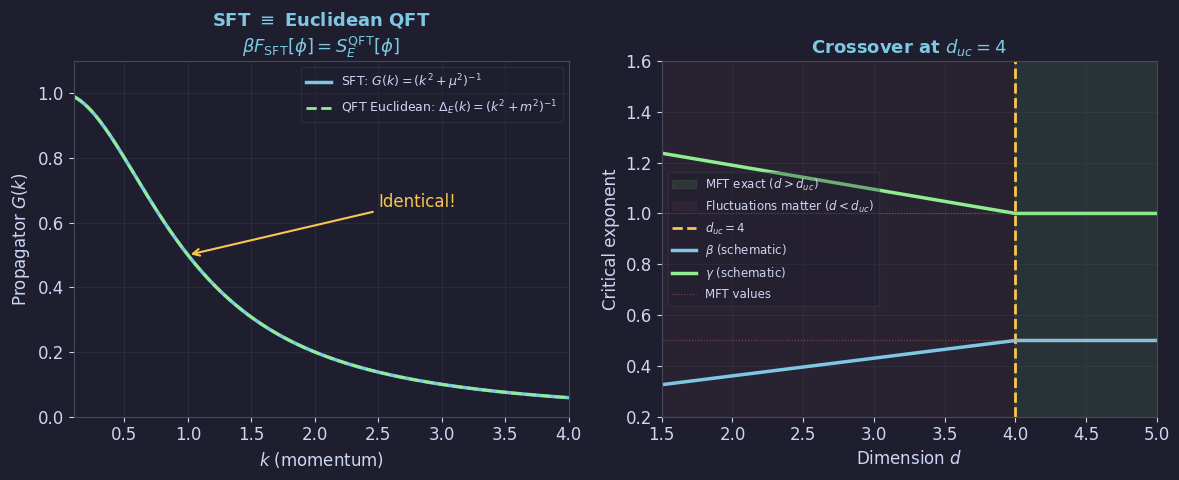

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04: QFT Analogy & Crossover at d_uc=4 (Ch 2.5) ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

ax = axes[0]
k = np.linspace(0.1, 4, 300)
ax.plot(k, 1/(k**2+1.0), color=BLUE, lw=2.5,
        label=r'SFT: $G(k)=(k^2+\mu^2)^{-1}$')
ax.plot(k, 1/(k**2+1.0), color=GREEN, lw=2.0, ls='--',
        label=r'QFT Euclidean: $\Delta_E(k)=(k^2+m^2)^{-1}$')
ax.annotate('Identical!', xy=(1.0, 0.5), xytext=(2.5, 0.65),
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.5),
            color=YELLOW, fontsize=12)
ax.set_xlabel(r'$k$ (momentum)'); ax.set_ylabel(r'Propagator $G(k)$')
ax.set_title(r'SFT $\equiv$ Euclidean QFT'+'\n'+
             r'$\beta F_{\rm SFT}[\phi]=S_E^{\rm QFT}[\phi]$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0.1,4); ax.set_ylim(0,1.1)

ax2 = axes[1]
d_arr = np.linspace(1.5, 5, 200)
ax2.axvspan(4, 5, color=GREEN, alpha=0.10, label=r'MFT exact ($d>d_{uc}$)')
ax2.axvspan(1.5, 4, color=RED, alpha=0.06, label=r'Fluctuations matter ($d<d_{uc}$)')
ax2.axvline(4, color=YELLOW, lw=2.0, ls='--', label=r'$d_{uc}=4$')
# Schematic exponent interpolation
beta_line  = np.where(d_arr<=4, 0.326 + (0.5-0.326)*(d_arr-1.5)/2.5, 0.5)
gamma_line = np.where(d_arr<=4, 1.237 - (1.237-1.0)*(d_arr-1.5)/2.5, 1.0)
ax2.plot(d_arr, beta_line,  color=BLUE,  lw=2.5, label=r'$\beta$ (schematic)')
ax2.plot(d_arr, gamma_line, color=GREEN, lw=2.5, label=r'$\gamma$ (schematic)')
ax2.axhline(0.5, color=RED, lw=0.8, ls=':', alpha=0.5, label='MFT values')
ax2.axhline(1.0, color=RED, lw=0.8, ls=':', alpha=0.5)
ax2.set_xlabel(r'Dimension $d$'); ax2.set_ylabel('Critical exponent')
ax2.set_title(r'Crossover at $d_{uc}=4$', color=BLUE)
ax2.legend(fontsize=8.5, labelcolor=FG, loc='center left')
ax2.set_xlim(1.5, 5); ax2.set_ylim(0.2, 1.6); ax2.grid(True)

plt.tight_layout(pad=1.2)
save('fig04_qft_analogy.png', fig)


---
## fig05 · Ginzburg Criterion (§2.4)

**Left**: Ratio $\langle(\delta m)^2\rangle/m_0^2$ diverges near $T_c$ for $d<4$ (MFT breaks down), vanishes for $d>4$. **Right**: Heat capacity from Gaussian theory with $\alpha_G=2-d/2$.

/tmp/ipykernel_8570/4111834296.py:59: RuntimeWarning: divide by zero encountered in divide
  C = -np.log(t_plot); C /= C[-1]
/tmp/ipykernel_8570/4111834296.py:59: RuntimeWarning: invalid value encountered in divide
  C = -np.log(t_plot); C /= C[-1]


  saved -> figures/ch02/fig05_ginzburg.png


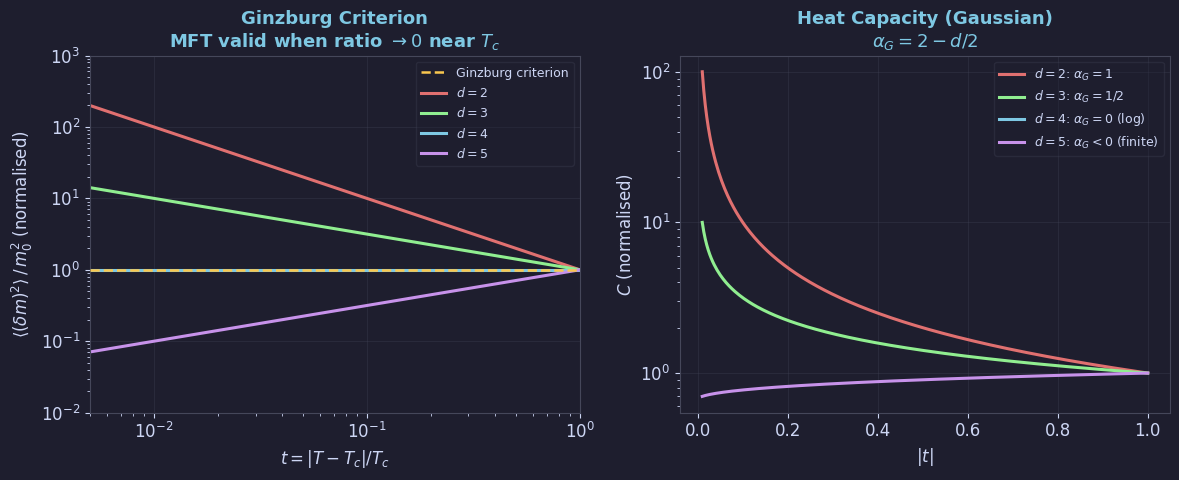

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig05: Ginzburg Criterion (Ch 2.4) ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

ax = axes[0]
t_arr = np.linspace(0.005, 1.0, 500)
ax.axhline(1, color=YELLOW, lw=1.8, ls='--', label='Ginzburg criterion', zorder=5)
for d, col, lab in [(2,RED,r'$d=2$'),(3,GREEN,r'$d=3$'),
                     (4,BLUE,r'$d=4$'),(5,PURPLE,r'$d=5$')]:
    # ratio = <(delta m)^2> / m0^2 ~ t^{(d-4)/2} / t = t^{(d-6)/2}
    exponent = (d-4)/2
    ratio = t_arr**exponent
    ratio /= ratio[-1]
    ax.loglog(t_arr, np.clip(ratio, 1e-3, 1e4),
              color=col, lw=2.2, label=lab)
ax.set_xlabel(r'$t=|T-T_c|/T_c$')
ax.set_ylabel(r'$\langle(\delta m)^2\rangle\,/\,m_0^2$ (normalised)')
ax.set_title('Ginzburg Criterion\n'+r'MFT valid when ratio $\to0$ near $T_c$',
             color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0.005, 1.0); ax.set_ylim(1e-2, 1e3)

ax2 = axes[1]
t_plot = np.linspace(0.01, 1.0, 300)
for d, col, lab in [(2,RED,r'$d=2$: $\alpha_G=1$'),
                     (3,GREEN,r'$d=3$: $\alpha_G=1/2$'),
                     (4,BLUE,r'$d=4$: $\alpha_G=0$ (log)'),
                     (5,PURPLE,r'$d=5$: $\alpha_G<0$ (finite)')]:
    alpha = 2 - d/2
    if alpha > 0:
        C = t_plot**(-alpha); C /= C[-1]
    elif alpha == 0:
        C = -np.log(t_plot); C /= C[-1]
    else:
        C = 1 - alpha*t_plot**(np.abs(alpha)); C /= C[-1]
    ax2.semilogy(t_plot, C, color=col, lw=2.2, label=lab)
ax2.set_xlabel(r'$|t|$'); ax2.set_ylabel(r'$C$ (normalised)')
ax2.set_title(r'Heat Capacity (Gaussian)'+'\n'+r'$\alpha_G = 2 - d/2$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)

plt.tight_layout(pad=1.2)
save('fig05_ginzburg.png', fig)


---
## Download All Figures

In [6]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/ch02'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) \
        if os.path.exists(OUTDIR) else []
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')

zip_name = 'sft_ch02_figures.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 5 figures:
  fig01_path_integral.png  (236 KB)
  fig02_correlation_fns.png  (246 KB)
  fig03_xi_scaling.png  (216 KB)
  fig04_qft_analogy.png  (141 KB)
  fig05_ginzburg.png  (156 KB)
Zip: sft_ch02_figures.zip  (946 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>